# SciPy：分布推定・残差・感度評価

対応する本文は [scipy.tex](../chapters/scipy.tex) である。コードセルを上から順にShift+Enterで実行する。各問の説明にある値や図と、セルの下に表示される結果を比べる。ファイルを作る問では、その直前に保存先を用意する。

## 入力を再現する

最初の2問には、本文と同じ順序で乱数を生成する。シードに加え、ライブラリの版も記録する。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.optimize import curve_fit

rng = np.random.default_rng(20260412)
synthetic_dt = rng.exponential(scale=120.0, size=5000)
x = np.linspace(0.0, 10.0, 80)
y_true = 2.5 * x + 1.2
sigma = np.full_like(x, 0.5)
y_obs = y_true + rng.normal(scale=sigma)
print("NumPy", np.__version__, "SciPy", scipy.__version__)

NumPy 2.5.4 SciPy 1.18.1


## 問1：平均的な待ち時間を求める

最初の入力は、平均120秒の指数分布から人工的に作った5000個の間隔である。生成に使う番号（乱数シード）を固定しているので、同じライブラリ環境なら同じ入力となる。

`expon.fit(..., floc=0)` は分布が始まる位置を0に固定し、待ち時間の大きさを表す `scale` を求める。この条件の指数分布では `scale` は標本平均と一致する。表示が115秒から125秒に入ることと、標本平均との一致を確認する。120秒との完全な一致は求めない。

標本平均とは、今回作った5000個の間隔の合計を5000で割った値である。`np.testing.assert_allclose()` は小さな丸めの差を許して比較する。`rtol=1e-12` は、答えの大きさに対し約1兆分の1までの差を許す指定である。

この後のセルにある `assert 条件` は、結果を自動で確認する命令である。条件が違っていればエラーで止まり、条件を満たせば次へ進む。何も表示されなくても、エラーが出なければその確認は通っている。画面の数値や図も、説明に示した値と比べる。

In [2]:
loc, scale = stats.expon.fit(synthetic_dt, floc=0)
print("loc =", loc, "scale [s] =", scale, "標本平均 [s] =", synthetic_dt.mean())
assert loc == 0 and 115 <= scale <= 125
np.testing.assert_allclose(scale, synthetic_dt.mean(), rtol=1e-12)

loc = 0.0 scale [s] = 119.02400782592979 標本平均 [s] = 119.02400782592979


## 問2：まず直線の傾きと切片を求める

本文と同じ5点で、`y = a * x + b` の `a` と `b` を求める。`a` は傾き、`b` はxが0のときのyである。`curve_fit()` は、各点のyと直線のyの差を二乗した合計が小さくなる値を探す。

In [3]:
def linear_example(x, a, b):
    return a * x + b

example_x = np.array([0., 1., 2., 3., 4.])
example_y = np.array([1.1, 2.0, 3.2, 4.1, 5.1])
example_params, example_cov = curve_fit(linear_example, example_x, example_y)
print("傾き:", round(example_params[0], 2))
print("切片:", round(example_params[1], 2))
np.testing.assert_allclose(example_params, [1.01, 1.08], rtol=0, atol=1e-6)

傾き: 1.01
切片: 1.08


傾きが約1.01、切片が約1.08になる。ここで調整した値をパラメータという。

### 各点の不確かさを使う

次は80点の人工データ `x` と `y_obs` を使う。`sigma` は各点のyの標準不確かさであり、大きい点ほどフィットへの寄与を小さくする。`absolute_sigma=True` は、この不確かさの大きさをパラメータの共分散の計算に使う指定である。

`popt` が傾きと切片、`pcov` がそれらの不確かさと共変動を表す共分散行列である。対角成分の平方根を取ると各パラメータの標準不確かさを得る。これは解の近傍での線形近似と独立な誤差を仮定した評価である。

データから直線の値を引いた差を残差という。上段にデータと直線、下段に残差を描く。傾きが2.3から2.7、切片が0.7から1.7に入り、下段にずれの並び方が表示されることを確認する。

`pcov` は2行2列である。`np.diag(pcov)` は左上と右下を取り出し、それぞれ傾きと切片の分散になる。`np.sqrt()` で平方根を求めると、元のパラメータと同じ単位の標準不確かさになる。

### 保存先を用意する

この後のセルではファイルを作る。次のセルを実行して、`notebooks/_outputs/09_scipy/` を用意する。表示された場所に結果が保存され、同名の実習用ファイルは再実行すると置き換わる。

Notebookは教材の `notebooks` フォルダー、または教材の一番上のフォルダーから実行する。`Path.cwd()` は現在のフォルダーを調べ、`mkdir()` は保存先を作る。

In [4]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "main.tex").is_file():
    raise FileNotFoundError("教材のフォルダーか notebooks フォルダーから実行してください。")
WORK = ROOT / "notebooks" / "_outputs" / "09_scipy"
WORK.mkdir(parents=True, exist_ok=True)
print("Python", sys.version.split()[0])
print("保存先:", WORK.relative_to(ROOT))

Python 3.12.14
保存先: notebooks/_outputs/09_scipy


パラメータ: [2.46032253 1.36833985] 標準不確かさ: [0.01912435 0.11076334]


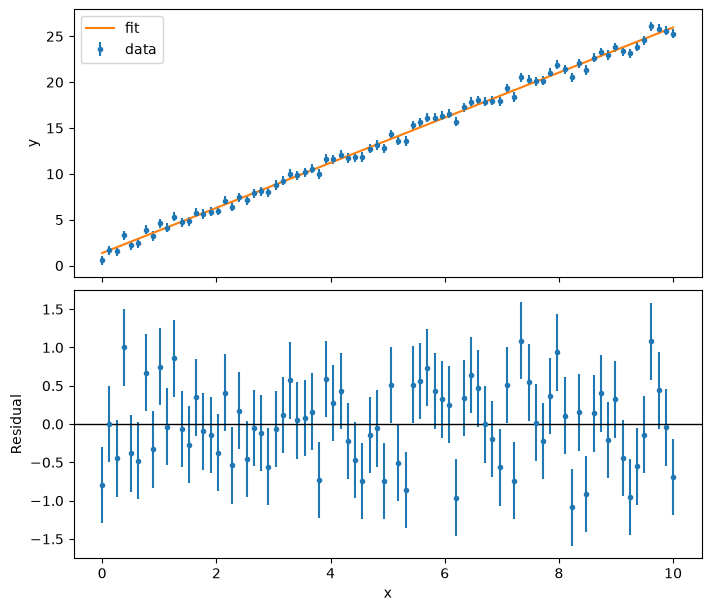

In [5]:
def model(x, a, b):
    return a * x + b

popt, pcov = curve_fit(model, x, y_obs, sigma=sigma, absolute_sigma=True)
errors = np.sqrt(np.diag(pcov))
residual = y_obs - model(x, *popt)
assert 2.3 <= popt[0] <= 2.7 and 0.7 <= popt[1] <= 1.7
print("パラメータ:", popt, "標準不確かさ:", errors)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7, 6), layout="constrained")
axes[0].errorbar(x, y_obs, yerr=sigma, fmt=".", label="data")
axes[0].plot(x, model(x, *popt), label="fit")
axes[0].set_ylabel("y")
axes[0].legend()
axes[1].errorbar(x, residual, yerr=sigma, fmt=".")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="x", ylabel="Residual")
fig.savefig(WORK / "linear_fit_residual.pdf")
plt.show()
plt.close(fig)
assert (WORK / "linear_fit_residual.pdf").exists()

## 問3：分布候補を比較する

通信なしの実行では検証用の指数乱数を使う。実データを比較する場合は `REAL_CSV` に取得済みカタログを指定する。検索条件、イベント種別、`magType`、マグニチュード下限を記録し、地域や期間を固定して解釈する。

ここでは短い待ち時間が多い指数分布と、形状パラメータが1のとき指数分布になるガンマ分布を候補にする。解析に使う値の集まりを標本という。

独立な標本を仮定して、各観測値での確率密度を掛け合わせた量を尤度といい、それを最大にするパラメータを探す方法を最尤推定という。計算では積の代わりに対数の和 `dist.logpdf(...).sum()` を使う。以下のLは最大尤度、logは自然対数である。AIC（赤池情報量規準）は、データへの合い方と調整値の数を合わせて比べる指標であり、`2k - 2 log L` とする。kはデータから推定するパラメータの数で、指数の自由母数は1個、位置を0に固定したガンマ分布は2個と数える。小さい AIC は候補間で相対的に良いことを示す。モデルの正しさの証明にはならない。AICを比べるときは、同じ標本と観測範囲を使う。

ECDF（経験累積分布関数）は、ある値以下にある標本の割合を表す。例えば5個中3個が100秒以下なら、100秒でのECDFは0.6である。モデルのCDF（累積分布関数）は、100秒以下となる確率をモデルから計算した値である。図は左から、密度のヒストグラム、ECDFとモデルCDF、両者の差を示す。[AICの定義はstatsmodels公式資料](https://www.statsmodels.org/stable/generated/statsmodels.tools.eval_measures.aic.html)でも確認できる。

synthetic exponential sample
         model  k  log_likelihood           AIC
0  exponential  1   -28896.626096  57795.252192
1        gamma  2   -28896.411344  57796.822687


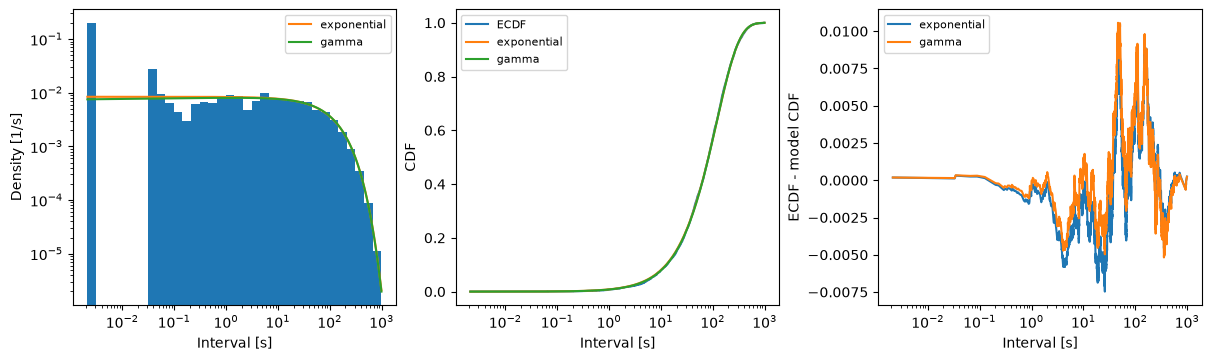

In [6]:
REAL_CSV = None  # 実カタログの Path を設定する。
values = synthetic_dt.copy()
source = "synthetic exponential sample"
if REAL_CSV is not None:
    catalog = pd.read_csv(REAL_CSV)
    stamps = pd.to_datetime(catalog["time"], utc=True, errors="raise").sort_values()
    values = stamps.diff().dropna().dt.total_seconds().to_numpy()
    source = "USGS catalog: " + Path(REAL_CSV).name
if not np.isfinite(values).all() or np.any(values <= 0):
    raise ValueError("連続分布の比較前に、非有限値・同時刻・非正の間隔の扱いを決めてください。")
if values.size < 20:
    raise ValueError("モデル比較の例には20件以上の間隔を用意してください。")
models = [("exponential", stats.expon, 1), ("gamma", stats.gamma, 2)]
fitted, rows = {}, []
for name, dist, k in models:
    params = dist.fit(values, floc=0)
    log_likelihood = float(dist.logpdf(values, *params).sum())
    fitted[name] = (dist, params)
    rows.append({"model": name, "k": k, "log_likelihood": log_likelihood, "AIC": 2*k - 2*log_likelihood})
comparison = pd.DataFrame(rows).sort_values("AIC")
print(source)
print(comparison)
comparison.to_csv(WORK / "model_comparison.csv", index=False)
ordered = np.sort(values)
ecdf = np.arange(1, len(values) + 1) / len(values)
grid = np.geomspace(ordered[0], ordered[-1], 300)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
axes[0].hist(values, bins=np.geomspace(ordered[0], ordered[-1], 35), density=True)
axes[0].set(xscale="log", yscale="log", xlabel="Interval [s]", ylabel="Density [1/s]")
axes[1].step(ordered, ecdf, where="post", label="ECDF")
for name, (dist, params) in fitted.items():
    axes[0].plot(grid, dist.pdf(grid, *params), label=name)
    axes[1].plot(grid, dist.cdf(grid, *params), label=name)
    axes[2].plot(ordered, ecdf - dist.cdf(ordered, *params), label=name)
axes[1].set(xscale="log", xlabel="Interval [s]", ylabel="CDF")
axes[2].set(xscale="log", xlabel="Interval [s]", ylabel="ECDF - model CDF")
for ax in axes:
    ax.legend(fontsize=8)
fig.savefig(WORK / "distribution_comparison.pdf")
plt.show()
plt.close(fig)

## 問4：下限を変えて感度を調べる

`t >= c` だけを残すと、観測される分布は条件付き分布となる。元の指数分布に位置0のまま当てはめると、切断の影響を無視して時定数を大きく見積もる。指数分布の無記憶性を仮定できる場合は `t - c` を推定する。下限を変えて使用件数と推定値を比較する。

`tau / sqrt(n)` は独立な指数標本というモデル下での漸近的な標準不確かさであり、地震カタログの相関やモデルの不適合を含まない。実データの確かな誤差評価には時間相関も検討する。

例えば下限cを30秒にし、80秒の間隔を残したなら、推定へ渡す値は `80 - 30 = 50` 秒となる。これは「すでに30秒待った後の、残りの待ち時間」を計算する操作である。指数分布でこの残り時間の分布が元と同じ形になる性質を、無記憶性という。

In [7]:
sensitivity = []
for cut in [0.0, 30.0, 60.0]:
    retained = values[values >= cut]
    if len(retained) < 2:
        continue
    excess = retained - cut
    tau = excess.mean()
    sensitivity.append({"cut_s": cut, "n": len(retained), "tau_s": tau,
                        "iid_model_se_s": tau / np.sqrt(len(retained)),
                        "naive_mean_s": retained.mean()})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(WORK / "sensitivity.csv", index=False)
print(sensitivity)

   cut_s     n       tau_s  iid_model_se_s  naive_mean_s
0    0.0  5000  119.024008        1.683254    119.024008
1   30.0  3896  118.572890        1.899660    148.572890
2   60.0  3018  119.031824        2.166723    179.031824


## 問5：Gutenberg–Richter 関係を検討する

完全性の下限 `M_c` 以上の連続マグニチュードで指数尾を仮定すると、`beta = 1 / mean(M - M_c)`、`b = beta / ln(10)` となる。累積件数の各点は同じ地震を共有するので、点ごとの独立な計数として最小二乗フィットしない。下では完全性の下限が既知の人工標本を使い、尤度に基づく推定と累積分布の表示を分ける。

実カタログでは `M_c` の妥当性、マグニチュードの丸め幅、尺度の混在、地域の検出能力、地震間の相関を評価する。丸めたマグニチュードへ連続値用の式をそのまま適用すると偏り得る。3行の動作確認用 CSV から物理的な b 値は推定しない。

完全性の下限とは、それ以上の規模の地震を十分に記録できているとみなす境界である。b値は、マグニチュードが1増えるごとに件数が何分の1になるかを表し、b=1なら約10分の1になる。次の `mc=3.0` は、人工標本を作るときに設定した既知の下限である。実際のカタログの下限を自動で求めたものではない。

人工標本の b: 1.0165076634077874 独立標本モデルでの標準不確かさ: 0.014375589238474781


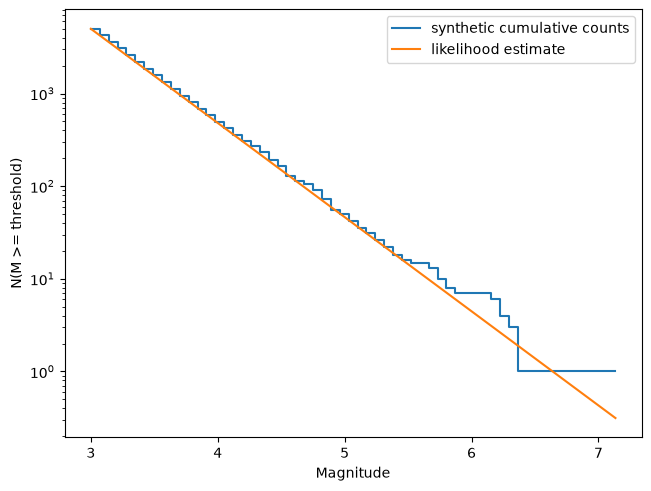

In [8]:
rng_gr = np.random.default_rng(42)
mc = 3.0
true_b = 1.0
magnitudes = mc + rng_gr.exponential(1 / (true_b * np.log(10)), 5000)
b_estimate = 1 / (np.log(10) * np.mean(magnitudes - mc))
b_iid_se = b_estimate / np.sqrt(len(magnitudes))
print("人工標本の b:", b_estimate, "独立標本モデルでの標準不確かさ:", b_iid_se)
assert 0.9 < b_estimate < 1.1
thresholds = np.linspace(mc, magnitudes.max(), 60)
cumulative = np.array([np.count_nonzero(magnitudes >= m) for m in thresholds])
fig, ax = plt.subplots(layout="constrained")
ax.step(thresholds, cumulative, where="post", label="synthetic cumulative counts")
ax.plot(thresholds, len(magnitudes) * 10**(-b_estimate * (thresholds-mc)), label="likelihood estimate")
ax.set(yscale="log", xlabel="Magnitude", ylabel="N(M >= threshold)")
ax.legend()
fig.savefig(WORK / "gutenberg_richter_synthetic.pdf")
plt.show()
plt.close(fig)